# InfraScan: Dataset Exploration and Analysis

**Project:** AI-Powered Crack & Damage Assessment for Civil Infrastructure

**Objective:** Explore and evaluate five infrastructure damage datasets for crack classification, road damage detection, and crack segmentation.

**Datasets:**
1. SDNET2018
2. Concrete Crack Images for Classification
3. RDD2022 — Road Damage Dataset
4. CrackForest Dataset (CFD)
5. Crack500

**Analysis:** Dataset structure, image counts, image dimensions, class distribution, annotations, data quality, and visual inspection.

In [ ]:
#Importing the Required libariries

# Core libraries
import os
import json
import random
from pathlib import Path
from collections import Counter

# Data analysis
import numpy as np
import pandas as pd

# Image processing and visualization
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Environment setup completed successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Environment setup completed successfully.
NumPy version: 2.1.3
Pandas version: 2.2.3


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/InfraScan")
DATA_DIR = PROJECT_DIR / "datasets"
EDA_DIR = PROJECT_DIR / "eda_results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
EDA_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("EDA results directory:", EDA_DIR)


Project directory: /content/InfraScan
Dataset directory: /content/InfraScan/datasets
EDA results directory: /content/InfraScan/eda_results


In [ ]:

import zipfile
from pathlib import Path

zip_path = Path("/content/DATA_Maguire_20180517_ALL.zip")

print("Valid ZIP:", zipfile.is_zipfile(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Number of archive entries:", len(z.namelist()))
    print("First 10 entries:")
    for name in z.namelist()[:10]:
        print(name)


Valid ZIP: True
Number of archive entries: 2
First 10 entries:
DATA_Maguire_20180517_ALL/ReadMe_SDNET2018 .txt
DATA_Maguire_20180517_ALL/SDNET2018.zip


In [ ]:

extract_dir = DATA_DIR / "SDNET2018"
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction completed.")
print("Dataset location:", extract_dir)

for item in sorted(extract_dir.iterdir()):
    print(item.name, "—", "Directory" if item.is_dir() else "File")


Extraction completed.
Dataset location: /content/InfraScan/datasets/SDNET2018
DATA_Maguire_20180517_ALL — Directory


In [ ]:

import zipfile
from pathlib import Path

outer_dir = DATA_DIR / "SDNET2018" / "DATA_Maguire_20180517_ALL"
inner_zip = outer_dir / "SDNET2018.zip"

# Verify the inner archive
assert inner_zip.exists(), f"Inner ZIP not found: {inner_zip}"
assert zipfile.is_zipfile(inner_zip), "Inner ZIP is invalid."

print("Inner ZIP size:", round(inner_zip.stat().st_size / (1024**2), 2), "MiB")
print("Inner ZIP is valid.")

# Extract the actual dataset
dataset_dir = DATA_DIR / "SDNET2018" / "images"
dataset_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(inner_zip, "r") as z:
    print("Number of archive entries:", len(z.namelist()))
    z.extractall(dataset_dir)

print("Extraction completed:", dataset_dir)

for item in sorted(dataset_dir.iterdir()):
    print(item.name, "—", "Directory" if item.is_dir() else "File")


Inner ZIP size: 503.81 MiB
Inner ZIP is valid.
Number of archive entries: 56101
Extraction completed: /content/InfraScan/datasets/SDNET2018/images
D — Directory
P — Directory
W — Directory


In [ ]:

from collections import Counter

# Actual image directory
dataset_dir = DATA_DIR / "SDNET2018" / "images"

# Supported image extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

summary = []
all_image_paths = []

for folder in sorted(dataset_dir.iterdir()):
    if folder.is_dir():
        images = [
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        all_image_paths.extend(images)

        summary.append({
            "Folder": folder.name,
            "Image Count": len(images),
            "Subfolder Count": sum(1 for p in folder.iterdir() if p.is_dir())
        })

summary_df = pd.DataFrame(summary)

print("Dataset directory:", dataset_dir)
print("Total images found:", len(all_image_paths))
display(summary_df)

# Save the summary for later reporting
summary_df.to_csv(EDA_DIR / "sdnet2018_folder_summary.csv", index=False)


Dataset directory: /content/InfraScan/datasets/SDNET2018/images
Total images found: 56092


,Folder,Image Count,Subfolder Count
0,D,13620,2
1,P,24334,2
2,W,18138,2


In [ ]:
# Read the SDNET2018 dataset documentation

outer_dir = DATA_DIR / "SDNET2018" / "DATA_Maguire_20180517_ALL"
readme_files = list(outer_dir.glob("ReadMe*"))

if readme_files:
    readme_path = readme_files[0]
    print("README file:", readme_path.name)

    with open(readme_path, "r", encoding="utf-8", errors="replace") as file:
        print(file.read())
else:
    print("README file not found.")

README file: ReadMe_SDNET2018 .txt

Dataset Title: 
SDNET2018: A concrete crack image dataset for machine learning applications

Researchers:
Marc Maguire
Utah State University
Utah State University, Department of Civil and Environmental Engineering, 4110 Old Main Hill, Logan, Utah, 84321-4110.
m.maguire@usu.edu
http://orcid.org/0000-0002-7897-0344?lang=en

Name and contact information of Co-PI:
Sattar Dorafshan
Utah State University
Utah State University, Department of Civil and Environmental Engineering, 4110 Old Main Hill, Logan, Utah, 84321-4110.
sattar.dor@aggiemail.usu.edu

Name and contact information of Co-PI:
Robert J. Thomas
Utah State University
Utah State University, Department of Civil and Environmental Engineering, 4110 Old Main Hill, Logan, Utah, 84321-4110.
robert.thomas@aggiemail.usu.edu

Project summary, description or abstract:
SDNET2018 is an annotated image dataset for training, validation, and benchmarking of artificial intelligence based crack detection algorithm

In [ ]:
# Inspect SDNET2018 class-folder structure

dataset_dir = DATA_DIR / "SDNET2018" / "images"
folder_details = []

for parent in sorted(dataset_dir.iterdir()):
    if parent.is_dir():
        for child in sorted(parent.iterdir()):
            if child.is_dir():
                count = sum(
                    1 for path in child.rglob("*")
                    if path.is_file()
                    and path.suffix.lower() in IMAGE_EXTENSIONS
                )
                folder_details.append({
                    "Parent Folder": parent.name,
                    "Subfolder": child.name,
                    "Image Count": count
                })

folder_details_df = pd.DataFrame(folder_details)
display(folder_details_df)

folder_details_df.to_csv(
    EDA_DIR / "sdnet2018_class_folder_summary.csv",
    index=False
)

,Parent Folder,Subfolder,Image Count
0,D,CD,2025
1,D,UD,11595
2,P,CP,2608
3,P,UP,21726
4,W,CW,3851
5,W,UW,14287


In [ ]:
# SDNET2018: class distribution analysis

class_counts = {
    "Bridge Decks": {"Cracked": 2025, "Uncracked": 11595},
    "Pavements": {"Cracked": 2608, "Uncracked": 21726},
    "Walls": {"Cracked": 3851, "Uncracked": 14287},
}

distribution_rows = []

for structure, classes in class_counts.items():
    total = sum(classes.values())

    for label, count in classes.items():
        distribution_rows.append({
            "Structure": structure,
            "Class": label,
            "Image Count": count,
            "Percentage within Structure": round(count / total * 100, 2),
            "Percentage of Entire Dataset": round(
                count / sum(sum(c.values()) for c in class_counts.values()) * 100,
                2
            )
        })

distribution_df = pd.DataFrame(distribution_rows)
display(distribution_df)

# Overall class summary
overall_df = (
    distribution_df.groupby("Class", as_index=False)["Image Count"]
    .sum()
)
overall_df["Percentage"] = (
    overall_df["Image Count"] / overall_df["Image Count"].sum() * 100
).round(2)

print("Overall class distribution:")
display(overall_df)

distribution_df.to_csv(
    EDA_DIR / "sdnet2018_class_distribution.csv",
    index=False
)
overall_df.to_csv(
    EDA_DIR / "sdnet2018_overall_class_distribution.csv",
    index=False
)

,Structure,Class,Image Count,Percentage within Structure,Percentage of Entire Dataset
0,Bridge Decks,Cracked,2025,14.87,3.61
1,Bridge Decks,Uncracked,11595,85.13,20.67
2,Pavements,Cracked,2608,10.72,4.65
3,Pavements,Uncracked,21726,89.28,38.73
4,Walls,Cracked,3851,21.23,6.87
5,Walls,Uncracked,14287,78.77,25.47


Overall class distribution:


,Class,Image Count,Percentage
0,Cracked,8484,15.13
1,Uncracked,47608,84.87


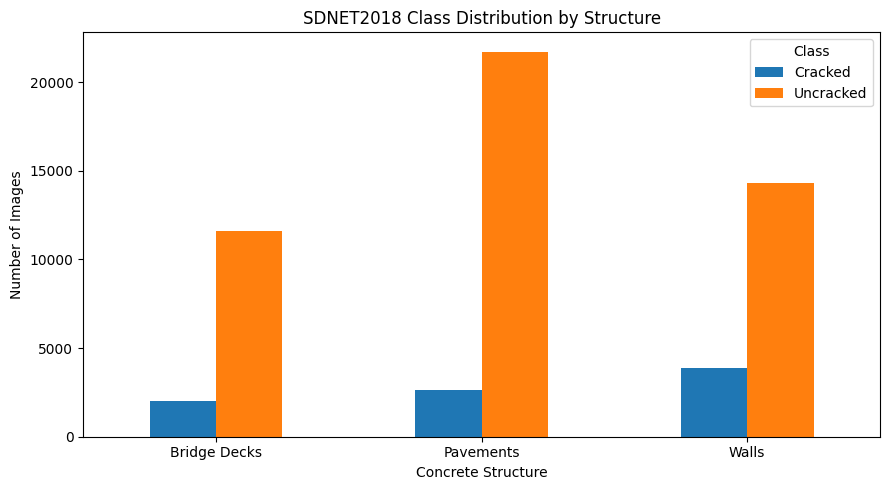

In [ ]:
# Visualize cracked vs uncracked images by structure

pivot_df = distribution_df.pivot(
    index="Structure",
    columns="Class",
    values="Image Count"
)

pivot_df = pivot_df[["Cracked", "Uncracked"]]

ax = pivot_df.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("SDNET2018 Class Distribution by Structure")
ax.set_xlabel("Concrete Structure")
ax.set_ylabel("Number of Images")
ax.legend(title="Class")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "sdnet2018_class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [ ]:
# SDNET2018: image dimensions and file integrity

from collections import Counter
from PIL import Image, UnidentifiedImageError

dataset_dir = DATA_DIR / "SDNET2018" / "images"

image_paths = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

# Inspect up to 500 images for dimensions and readability
sample_paths = random.sample(
    image_paths,
    min(500, len(image_paths))
)

dimension_counts = Counter()
mode_counts = Counter()
unreadable_images = []

for path in sample_paths:
    try:
        with Image.open(path) as img:
            dimension_counts[img.size] += 1
            mode_counts[img.mode] += 1
            img.verify()
    except (OSError, UnidentifiedImageError, ValueError):
        unreadable_images.append(str(path))

print("Total dataset images:", len(image_paths))
print("Images sampled:", len(sample_paths))
print("Sampled image dimensions:", dimension_counts)
print("Sampled image modes:", mode_counts)
print("Unreadable images in sample:", len(unreadable_images))

if unreadable_images:
    print("Examples of unreadable files:", unreadable_images[:5])

Total dataset images: 56092
Images sampled: 500
Sampled image dimensions: Counter({(256, 256): 500})
Sampled image modes: Counter({'RGB': 500})
Unreadable images in sample: 0


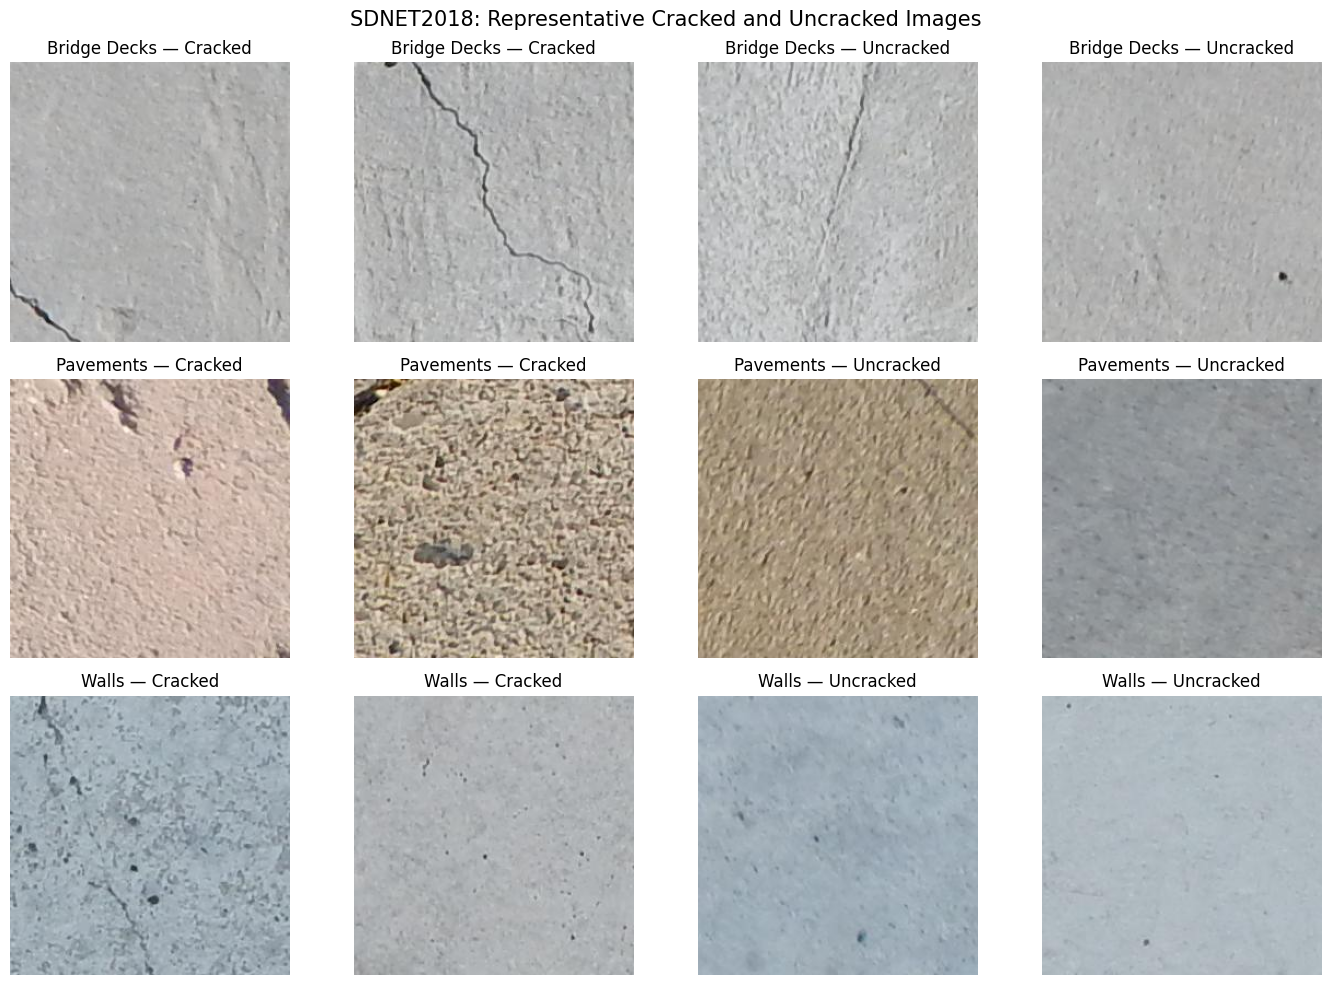

In [ ]:
# SDNET2018: visualize representative images by structure and class

import matplotlib.pyplot as plt
from pathlib import Path

dataset_dir = DATA_DIR / "SDNET2018" / "images"

sample_folders = [
    ("Bridge Decks - Cracked", dataset_dir / "D" / "CD"),
    ("Bridge Decks - Uncracked", dataset_dir / "D" / "UD"),
    ("Pavements - Cracked", dataset_dir / "P" / "CP"),
    ("Pavements - Uncracked", dataset_dir / "P" / "UP"),
    ("Walls - Cracked", dataset_dir / "W" / "CW"),
    ("Walls - Uncracked", dataset_dir / "W" / "UW"),
]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("SDNET2018: Representative Cracked and Uncracked Images",
             fontsize=15)

for row, (label_cracked, folder_cracked) in enumerate(
    [sample_folders[0:2], sample_folders[2:4], sample_folders[4:6]]
):
    for col, (label, folder) in enumerate(
        [(label_cracked[0], folder_cracked)]
    ):
        pass

for row, (structure, cracked_folder, uncracked_folder) in enumerate([
    ("Bridge Decks", dataset_dir / "D" / "CD", dataset_dir / "D" / "UD"),
    ("Pavements", dataset_dir / "P" / "CP", dataset_dir / "P" / "UP"),
    ("Walls", dataset_dir / "W" / "CW", dataset_dir / "W" / "UW"),
]):
    for col, (class_name, folder) in enumerate([
        ("Cracked", cracked_folder),
        ("Uncracked", uncracked_folder),
    ]):
        images = sorted(folder.glob("*.jpg"))
        chosen = random.sample(images, min(2, len(images)))

        for offset, image_path in enumerate(chosen):
            with Image.open(image_path) as img:
                axes[row, col * 2 + offset].imshow(img.convert("RGB"))

            axes[row, col * 2 + offset].set_title(
                f"{structure} — {class_name}"
            )
            axes[row, col * 2 + offset].axis("off")

plt.tight_layout()
plt.savefig(
    EDA_DIR / "sdnet2018_sample_images.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

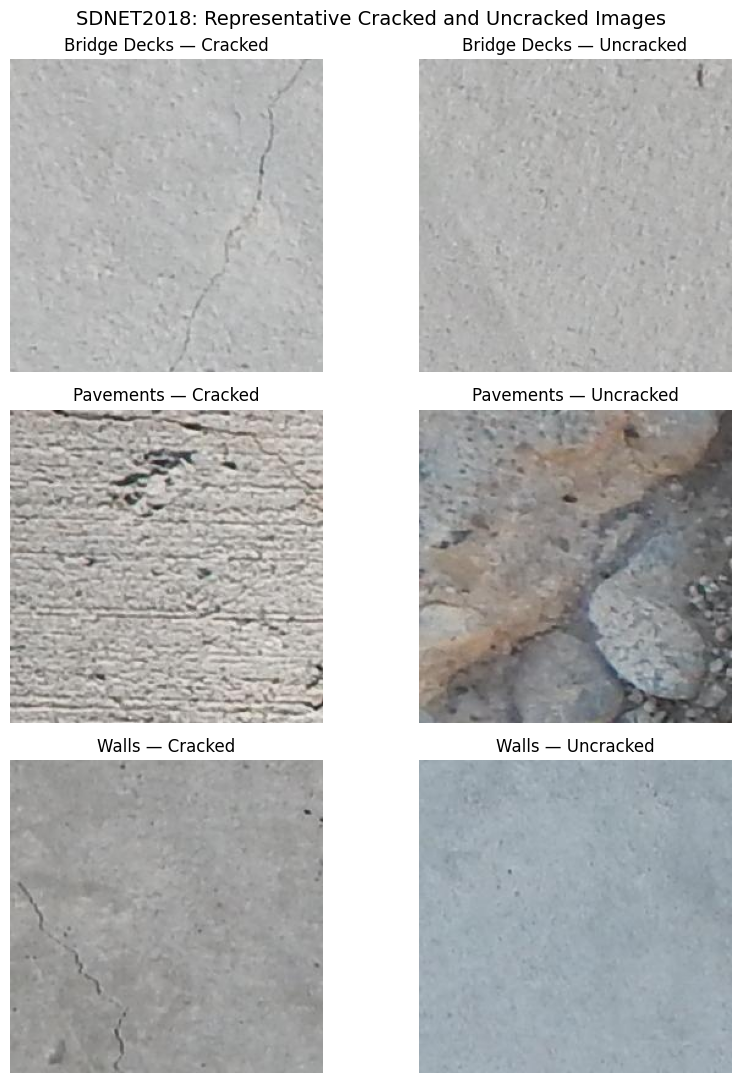

In [ ]:
# SDNET2018: representative image comparison

fig, axes = plt.subplots(3, 2, figsize=(9, 11))

structures = [
    ("Bridge Decks", "D", "CD", "UD"),
    ("Pavements", "P", "CP", "UP"),
    ("Walls", "W", "CW", "UW"),
]

for row, (structure, parent, cracked, uncracked) in enumerate(structures):
    for col, (class_name, folder_name) in enumerate([
        ("Cracked", cracked),
        ("Uncracked", uncracked),
    ]):
        folder = dataset_dir / parent / folder_name
        candidates = list(folder.glob("*.jpg"))
        image_path = random.choice(candidates)

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(f"{structure} — {class_name}")
        axes[row, col].axis("off")

plt.suptitle(
    "SDNET2018: Representative Cracked and Uncracked Images",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    EDA_DIR / "sdnet2018_sample_images.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### SDNET2018 — EDA Summary

- **Dataset size:** 56,092 images.
- **Image format:** JPG, RGB color images.
- **Image dimensions:** The 500-image sample contained only 256 × 256 images.
- **Structure categories:** Bridge decks, pavements, and walls.
- **Class labels:** Cracked and uncracked.
- **Class distribution:** 8,484 cracked images (15.13%) and 47,608 uncracked images (84.87%).
- **Class imbalance:** Uncracked images substantially outnumber cracked images, particularly in the pavement subset.
- **Visual observations:** Images exhibit variation in concrete texture, lighting, surface roughness, and visible defects. Some crack-like patterns may be difficult to distinguish from surface texture through visual inspection alone.

**Conclusion:** SDNET2018 provides a substantial image dataset for concrete crack classification. Its class imbalance should be considered when designing the training, validation, and evaluation strategy.

In [ ]:
# Verify SDNET2018 EDA artifacts

for path in sorted(EDA_DIR.glob("sdnet2018_*")):
    print(f"{path.name} — {path.stat().st_size / 1024:.1f} KB")

sdnet2018_class_distribution.csv — 0.3 KB
sdnet2018_class_distribution.png — 44.1 KB
sdnet2018_class_folder_summary.csv — 0.1 KB
sdnet2018_folder_summary.csv — 0.1 KB
sdnet2018_overall_class_distribution.csv — 0.1 KB
sdnet2018_sample_images.png — 930.4 KB


Dataset-2:

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/InfraScan")
DATA_DIR = PROJECT_DIR / "datasets"
EDA_DIR = PROJECT_DIR / "eda_results"

DATASET2_DIR = DATA_DIR / "Concrete_Crack_Classification"
DATASET2_RAW_DIR = DATASET2_DIR / "raw"
DATASET2_IMAGES_DIR = DATASET2_DIR / "images"

DATASET2_RAW_DIR.mkdir(parents=True, exist_ok=True)
DATASET2_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset 2 directories initialized.")
print("Raw directory:", DATASET2_RAW_DIR)
print("Images directory:", DATASET2_IMAGES_DIR)

Dataset 2 directories initialized.
Raw directory: /content/InfraScan/datasets/Concrete_Crack_Classification/raw
Images directory: /content/InfraScan/datasets/Concrete_Crack_Classification/images


In [ ]:
import zipfile

filename = "5y9wdsg2zt-2.zip"

candidates = [
    Path("/content") / filename,
    DATASET2_RAW_DIR / filename
]

archive_path = next(
    (p for p in candidates if p.exists()),
    None
)

if archive_path is None:
    print("ZIP not found. Please upload it again.")
else:
    print("Archive found:", archive_path)
    print(f"Size: {archive_path.stat().st_size / (1024**2):.2f} MiB")

    if zipfile.is_zipfile(archive_path):
        with zipfile.ZipFile(archive_path, "r") as z:
            entries = z.namelist()
            print("Valid ZIP archive.")
            print("Total entries:", len(entries))
            print("\nFirst 20 entries:")
            for entry in entries[:20]:
                print(entry)
    else:
        print("The file is not a valid ZIP archive.")

Archive found: /content/5y9wdsg2zt-2.zip
Size: 229.69 MiB
Valid ZIP archive.
Total entries: 1

First 20 entries:
Concrete Crack Images for Classification.rar


In [ ]:
import zipfile
import shutil
from pathlib import Path

archive_path = Path("/content/5y9wdsg2zt-2.zip")

with zipfile.ZipFile(archive_path, "r") as z:
    z.extractall(DATASET2_RAW_DIR)

rar_path = DATASET2_RAW_DIR / "Concrete Crack Images for Classification.rar"

print("RAR file extracted:", rar_path.exists())
if rar_path.exists():
    print(f"RAR size: {rar_path.stat().st_size / (1024**2):.2f} MiB")

RAR file extracted: True
RAR size: 230.18 MiB


In [ ]:
!apt-get -qq update
!apt-get -qq install -y unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import subprocess

result = subprocess.run(
    [
        "unrar", "x", "-o+", str(rar_path),
        str(DATASET2_IMAGES_DIR) + "/"
    ],
    capture_output=True,
    text=True
)

print(result.stdout[-4000:])
if result.returncode != 0:
    print("Extraction error:")
    print(result.stderr[-2000:])
else:
    print("RAR extraction completed.")

k_Classification/images/Negative/19967.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19968.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19969.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19970.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19971.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19972.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19973.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19974.jpg      99%  OK 
Extracting  /content/InfraScan/datasets/Concrete_Crack_Classification/images/Negative/19975.jpg     

In [ ]:
# Dataset 2: inspect folder structure and count images

from pathlib import Path
import pandas as pd

dataset2_images_dir = DATASET2_IMAGES_DIR

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

folder_summary = []
class_image_paths = {}

for folder in sorted(dataset2_images_dir.iterdir()):
    if folder.is_dir():
        images = [
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        class_image_paths[folder.name] = images

        folder_summary.append({
            "Class": folder.name,
            "Image Count": len(images)
        })

folder_summary_df = pd.DataFrame(folder_summary)

print("Dataset directory:", dataset2_images_dir)
print("Total images:", sum(row["Image Count"] for row in folder_summary))
display(folder_summary_df)

folder_summary_df.to_csv(
    EDA_DIR / "concrete_crack_classification_folder_summary.csv",
    index=False
)

Dataset directory: /content/InfraScan/datasets/Concrete_Crack_Classification/images
Total images: 40000


,Class,Image Count
0,Negative,20000
1,Positive,20000


In [ ]:
# Inspect a sample of image dimensions and readability

from PIL import Image, UnidentifiedImageError
from collections import Counter
import random

all_images = [
    path
    for paths in class_image_paths.values()
    for path in paths
]

sample_paths = random.sample(all_images, min(500, len(all_images)))

dimension_counts = Counter()
mode_counts = Counter()
unreadable_images = []

for path in sample_paths:
    try:
        with Image.open(path) as img:
            dimension_counts[img.size] += 1
            mode_counts[img.mode] += 1
            img.verify()
    except (OSError, UnidentifiedImageError, ValueError):
        unreadable_images.append(str(path))

print("Total images:", len(all_images))
print("Sample size:", len(sample_paths))
print("Dimensions:", dimension_counts)
print("Image modes:", mode_counts)
print("Unreadable images in sample:", len(unreadable_images))

Total images: 40000
Sample size: 500
Dimensions: Counter({(227, 227): 500})
Image modes: Counter({'RGB': 500})
Unreadable images in sample: 0


Concrete Crack Images for Classification — Class Distribution


,Class,Image Count,Percentage
0,Negative,20000,50.0
1,Positive,20000,50.0


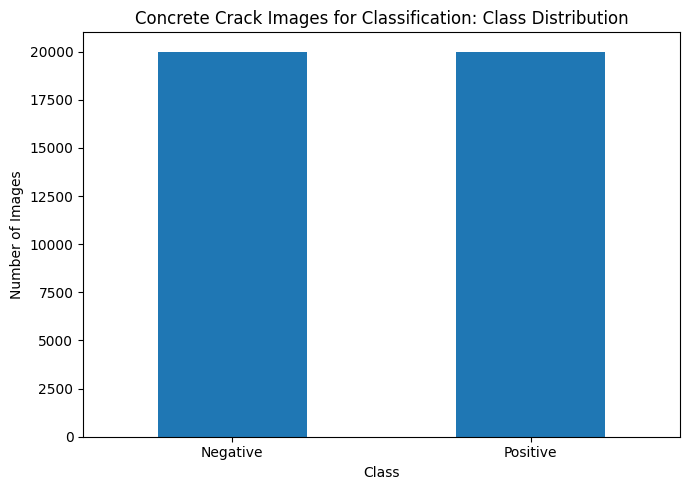

In [ ]:
# Dataset 2: class distribution analysis

distribution_df = folder_summary_df.copy()

distribution_df["Percentage"] = (
    distribution_df["Image Count"]
    / distribution_df["Image Count"].sum()
    * 100
).round(2)

print("Concrete Crack Images for Classification — Class Distribution")
display(distribution_df)

distribution_df.to_csv(
    EDA_DIR / "concrete_crack_classification_class_distribution.csv",
    index=False
)

# Plot class distribution
fig, ax = plt.subplots(figsize=(7, 5))

distribution_df.plot(
    x="Class",
    y="Image Count",
    kind="bar",
    ax=ax,
    legend=False,
    rot=0
)

ax.set_title("Concrete Crack Images for Classification: Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")

plt.tight_layout()
plt.savefig(
    EDA_DIR / "concrete_crack_classification_class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

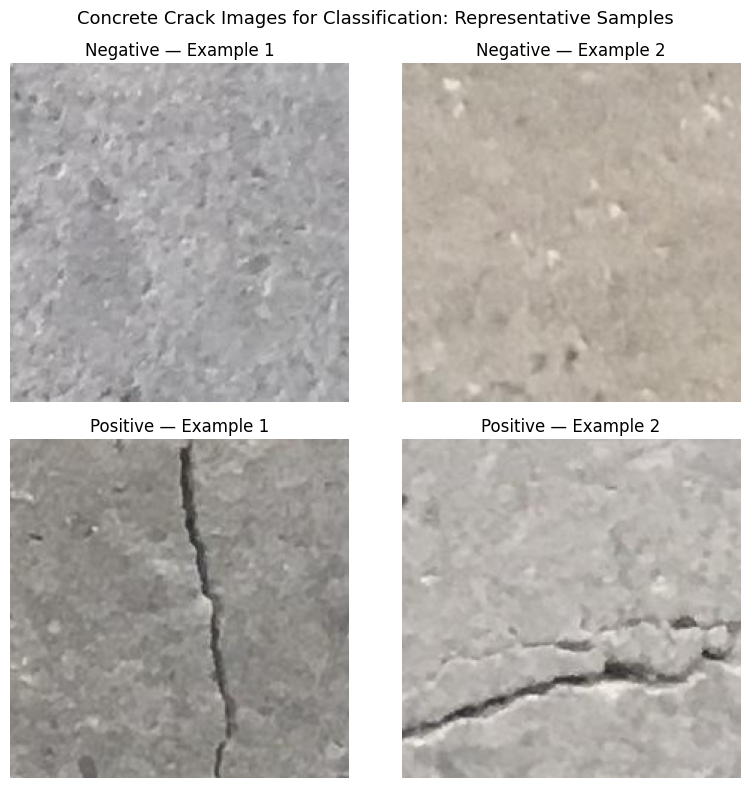

In [ ]:
# Dataset 2: representative images from each class

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for row, class_name in enumerate(sorted(class_image_paths)):
    selected_images = random.sample(
        class_image_paths[class_name],
        min(2, len(class_image_paths[class_name]))
    )

    for col, image_path in enumerate(selected_images):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(f"{class_name} — Example {col + 1}")
        axes[row, col].axis("off")

plt.suptitle(
    "Concrete Crack Images for Classification: Representative Samples",
    fontsize=13
)
plt.tight_layout()

plt.savefig(
    EDA_DIR / "concrete_crack_classification_sample_images.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### Dataset 2 — Concrete Crack Images for Classification: EDA Summary

- **Total images:** 40,000.
- **Class folders:** Negative and Positive.
- **Class distribution:** 20,000 images per class, representing 50% each.
- **Image dimensions:** All 500 sampled images were 227 × 227 pixels.
- **Image format:** RGB color images in the inspected sample.
- **Sample readability:** No unreadable images were found in the 500-image sample.
- **Class balance:** The dataset is balanced across its two folder labels.

**Conclusion:** This dataset is suitable for initial binary crack-classification experiments. Its balanced class distribution provides a useful contrast with SDNET2018, where uncracked images substantially outnumber cracked images.

**Validation limitation:** Image dimensions, color mode, and readability were checked on a 500-image sample rather than the complete dataset.

# ***Dataset-3***

In [ ]:
# Dataset 3: CrackForest Dataset

DATASET4_DIR = DATA_DIR / "CrackForest"
DATASET4_RAW_DIR = DATASET4_DIR / "raw"
DATASET4_IMAGES_DIR = DATASET4_DIR / "images"
DATASET4_MASKS_DIR = DATASET4_DIR / "masks"

for directory in [
    DATASET4_RAW_DIR,
    DATASET4_IMAGES_DIR,
    DATASET4_MASKS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("CrackForest workspace initialized.")
print("Raw archive directory:", DATASET4_RAW_DIR)
print("Image directory:", DATASET4_IMAGES_DIR)
print("Mask directory:", DATASET4_MASKS_DIR)

CrackForest workspace initialized.
Raw archive directory: /content/InfraScan/datasets/CrackForest/raw
Image directory: /content/InfraScan/datasets/CrackForest/images
Mask directory: /content/InfraScan/datasets/CrackForest/masks


In [ ]:
from pathlib import Path
import shutil

filename = "CrackForest-dataset-master.zip"
source = Path("/content") / filename

if source.exists():
    DATASET4_RAW_DIR.mkdir(parents=True, exist_ok=True)
    destination = DATASET4_RAW_DIR / filename
    shutil.move(str(source), str(destination))
    print("ZIP moved successfully:", destination)
    print(f"Size: {destination.stat().st_size / (1024**2):.2f} MiB")
else:
    print("ZIP not found directly in /content.")
    print("Files currently in /content:")
    print("\n".join(p.name for p in Path("/content").iterdir()))

ZIP moved successfully: /content/InfraScan/datasets/CrackForest/raw/CrackForest-dataset-master.zip
Size: 9.66 MiB


In [ ]:
import zipfile

archive_path = DATASET4_RAW_DIR / "CrackForest-dataset-master.zip"

print("Valid ZIP:", zipfile.is_zipfile(archive_path))

with zipfile.ZipFile(archive_path, "r") as z:
    entries = z.namelist()

    print("Total archive entries:", len(entries))
    print("\nFirst 25 entries:")
    print("\n".join(entries[:25]))

Valid ZIP: True
Total archive entries: 397

First 25 entries:
CrackForest-dataset-master/
CrackForest-dataset-master/README.md
CrackForest-dataset-master/groundTruth/
CrackForest-dataset-master/groundTruth/001.mat
CrackForest-dataset-master/groundTruth/002.mat
CrackForest-dataset-master/groundTruth/003.mat
CrackForest-dataset-master/groundTruth/004.mat
CrackForest-dataset-master/groundTruth/005.mat
CrackForest-dataset-master/groundTruth/006.mat
CrackForest-dataset-master/groundTruth/007.mat
CrackForest-dataset-master/groundTruth/008.mat
CrackForest-dataset-master/groundTruth/009.mat
CrackForest-dataset-master/groundTruth/010.mat
CrackForest-dataset-master/groundTruth/011.mat
CrackForest-dataset-master/groundTruth/012.mat
CrackForest-dataset-master/groundTruth/013.mat
CrackForest-dataset-master/groundTruth/014.mat
CrackForest-dataset-master/groundTruth/015.mat
CrackForest-dataset-master/groundTruth/016.mat
CrackForest-dataset-master/groundTruth/017.mat
CrackForest-dataset-master/groundT

In [ ]:
import zipfile

DATASET4_EXTRACT_DIR = DATASET4_DIR / "source"
DATASET4_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive_path, "r") as z:
    z.extractall(DATASET4_EXTRACT_DIR)

print("Extraction completed.")
print("Extracted to:", DATASET4_EXTRACT_DIR)

dataset_root = DATASET4_EXTRACT_DIR / "CrackForest-dataset-master"

for folder_name in ["image", "groundTruth", "seg"]:
    folder_path = dataset_root / folder_name

    if folder_path.exists():
        files_in_folder = [p for p in folder_path.iterdir() if p.is_file()]
        print(f"{folder_name}: {len(files_in_folder)} files")
    else:
        print(f"{folder_name}: folder not found")

Extraction completed.
Extracted to: /content/InfraScan/datasets/CrackForest/source
image: 156 files
groundTruth: 118 files
seg: 118 files


In [ ]:
from collections import Counter
from scipy.io import loadmat

for folder_name in ["image", "groundTruth", "seg"]:
    folder_path = dataset_root / folder_name

    if folder_path.exists():
        extensions = Counter(
            p.suffix.lower()
            for p in folder_path.iterdir()
            if p.is_file()
        )
        print(f"\n{folder_name} file extensions:", dict(extensions))

# Inspect one ground-truth MATLAB annotation
mat_files = sorted((dataset_root / "groundTruth").glob("*.mat"))

if mat_files:
    sample_mat = loadmat(mat_files[0])

    print("\nSample annotation:", mat_files[0].name)
    print("MATLAB keys:", [k for k in sample_mat.keys() if not k.startswith("__")])

    for key, value in sample_mat.items():
        if not key.startswith("__"):
            print(
                f"{key}: type={type(value).__name__}, "
                f"shape={getattr(value, 'shape', 'N/A')}, "
                f"dtype={getattr(value, 'dtype', 'N/A')}"
            )


image file extensions: {'.jpg': 155, '.rar': 1}

groundTruth file extensions: {'.mat': 118}

seg file extensions: {'.seg': 118}

Sample annotation: 001.mat
MATLAB keys: ['groundTruth']
groundTruth: type=ndarray, shape=(1, 1), dtype=[('Segmentation', 'O'), ('Boundaries', 'O')]


In [ ]:
from PIL import Image, UnidentifiedImageError
from scipy.io import loadmat
from collections import Counter
import numpy as np

image_dir = dataset_root / "image"
ground_truth_dir = dataset_root / "groundTruth"
seg_dir = dataset_root / "seg"

# 1. Inspect JPG images
image_files = sorted(image_dir.glob("*.jpg"))
image_sizes = Counter()
unreadable_images = []

for path in image_files:
    try:
        with Image.open(path) as img:
            image_sizes[(img.width, img.height)] += 1
            img.verify()
    except Exception:
        unreadable_images.append(path.name)

print("JPG image count:", len(image_files))
print("Image dimensions (width, height):", dict(image_sizes))
print("Unreadable JPG files:", len(unreadable_images))
if unreadable_images:
    print("Examples:", unreadable_images[:10])

# 2. Inspect ground-truth annotation structure
mat_files = sorted(ground_truth_dir.glob("*.mat"))
sample_mat = loadmat(mat_files[0], squeeze_me=True, struct_as_record=False)
gt = sample_mat["groundTruth"]

print("\nSample annotation:", mat_files[0].name)
print("Ground-truth object type:", type(gt).__name__)
print("Available fields:", getattr(gt, "_fieldnames", None))

if hasattr(gt, "Segmentation"):
    segmentation = np.asarray(gt.Segmentation)
    print("Segmentation shape:", segmentation.shape)
    print("Segmentation dtype:", segmentation.dtype)
    print("Segmentation unique values (up to 20):",
          np.unique(segmentation)[:20])

if hasattr(gt, "Boundaries"):
    boundaries = np.asarray(gt.Boundaries)
    print("Boundaries shape:", boundaries.shape)
    print("Boundaries dtype:", boundaries.dtype)
    print("Boundaries unique values (up to 20):",
          np.unique(boundaries)[:20])

# 3. Check filename matching
image_stems = {p.stem for p in image_files}
mat_stems = {p.stem for p in mat_files}
seg_stems = {p.stem for p in seg_dir.glob("*.seg")}

print("\nMatching filenames:")
print("JPGs with matching .mat:", len(image_stems & mat_stems))
print("JPGs with matching .seg:", len(image_stems & seg_stems))
print("JPGs without .mat:", sorted(image_stems - mat_stems)[:15])

JPG image count: 155
Image dimensions (width, height): {(480, 320): 153, (320, 480): 2}
Unreadable JPG files: 0

Sample annotation: 001.mat
Ground-truth object type: mat_struct
Available fields: ['Segmentation', 'Boundaries']
Segmentation shape: (320, 480)
Segmentation dtype: uint8
Segmentation unique values (up to 20): [1 2]
Boundaries shape: (320, 480)
Boundaries dtype: uint8
Boundaries unique values (up to 20): [0 1]

Matching filenames:
JPGs with matching .mat: 118
JPGs with matching .seg: 118
JPGs without .mat: ['201', '202', '203', '204', '205', '206', '207', '208', '301', '302', '303', '304', '305', '306', '307']


Annotation summary:


,filename,height,width,segmentation_values,boundary_values,segmentation_value_1_pixels,segmentation_value_2_pixels,boundary_positive_pixels
0,001,320,480,"1,2","0,1",151769,1831,1177
1,002,320,480,"1,2","0,1",148601,4999,2643
2,003,320,480,"1,2","0,1",151171,2429,1550
3,004,320,480,"1,2","0,1",151583,2017,1407
4,005,320,480,"1,2","0,1",151859,1741,1079



Annotation count: 118

Annotation dimensions:


,height,width,count
0,320,480,118



Segmentation value combinations:


,values,count
0,"1,2",96
1,"1,2,3",17
2,"1,2,3,4",5



Boundary value combinations:


,values,count
0,"0,1",118


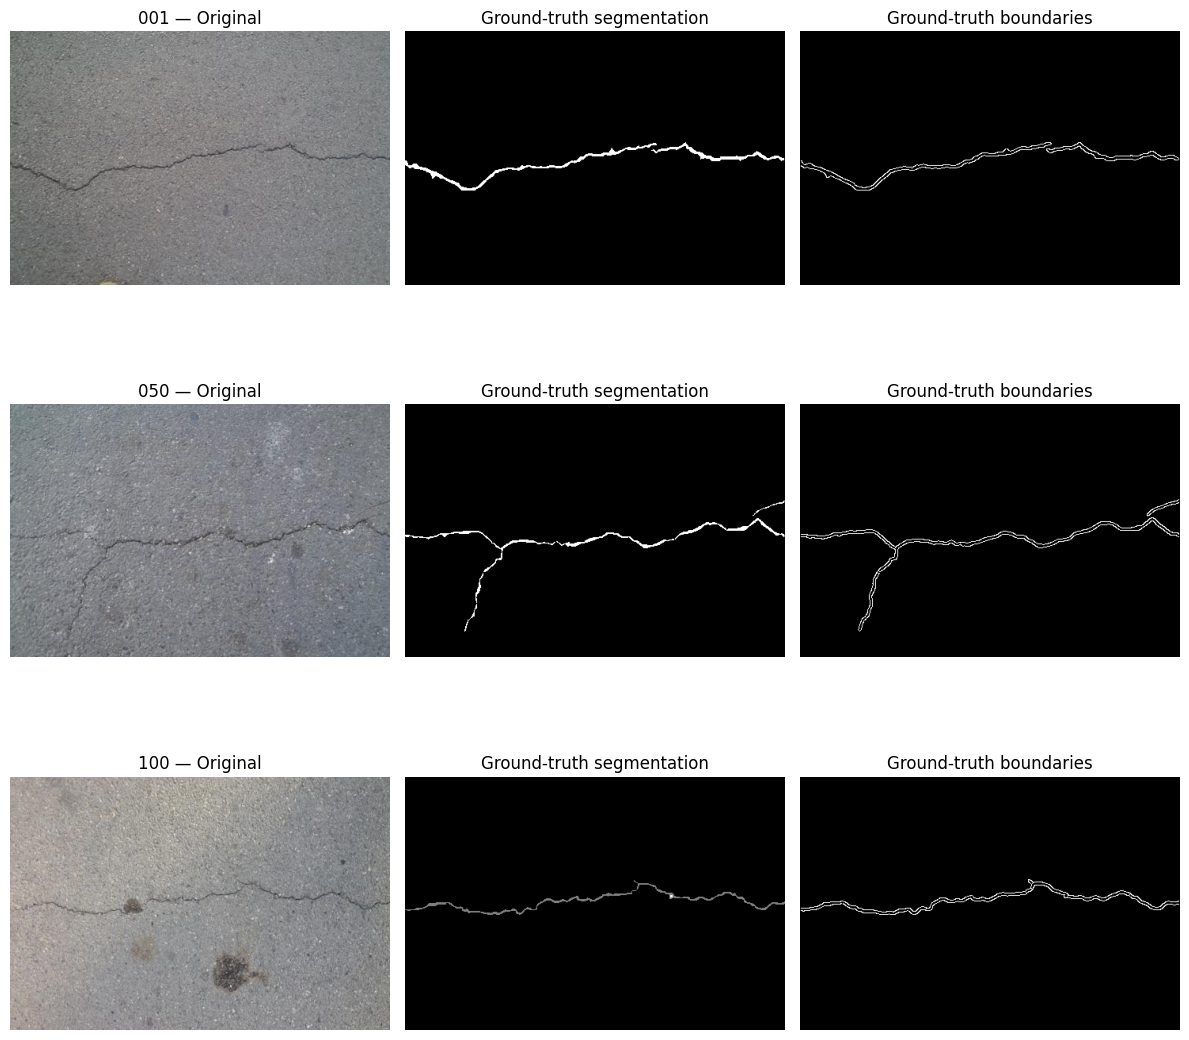

In [ ]:
from scipy.io import loadmat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Summarize all ground-truth annotations
annotation_rows = []

for mat_path in sorted(ground_truth_dir.glob("*.mat")):
    data = loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    gt = data["groundTruth"]

    segmentation = np.asarray(gt.Segmentation)
    boundaries = np.asarray(gt.Boundaries)

    annotation_rows.append({
        "filename": mat_path.stem,
        "height": segmentation.shape[0],
        "width": segmentation.shape[1],
        "segmentation_values": ",".join(map(str, np.unique(segmentation))),
        "boundary_values": ",".join(map(str, np.unique(boundaries))),
        "segmentation_value_1_pixels": int(np.sum(segmentation == 1)),
        "segmentation_value_2_pixels": int(np.sum(segmentation == 2)),
        "boundary_positive_pixels": int(np.sum(boundaries == 1)),
    })

annotation_df = pd.DataFrame(annotation_rows)

print("Annotation summary:")
display(annotation_df.head())
print("\nAnnotation count:", len(annotation_df))
print("\nAnnotation dimensions:")
display(annotation_df.groupby(["height", "width"]).size().reset_index(name="count"))
print("\nSegmentation value combinations:")
display(annotation_df["segmentation_values"].value_counts().rename_axis("values").reset_index(name="count"))
print("\nBoundary value combinations:")
display(annotation_df["boundary_values"].value_counts().rename_axis("values").reset_index(name="count"))

# Save annotation summary
annotation_df.to_csv(EDA_DIR / "crackforest_annotation_summary.csv", index=False)

# Visualize three annotated samples
sample_ids = ["001", "050", "100"]
fig, axes = plt.subplots(len(sample_ids), 3, figsize=(12, 4 * len(sample_ids)))

for row, sample_id in enumerate(sample_ids):
    image_path = image_dir / f"{sample_id}.jpg"
    mat_path = ground_truth_dir / f"{sample_id}.mat"

    data = loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    gt = data["groundTruth"]

    with Image.open(image_path) as img:
        axes[row, 0].imshow(img.convert("RGB"))
    axes[row, 0].set_title(f"{sample_id} — Original")
    axes[row, 1].imshow(gt.Segmentation, cmap="gray")
    axes[row, 1].set_title("Ground-truth segmentation")
    axes[row, 2].imshow(gt.Boundaries, cmap="gray")
    axes[row, 2].set_title("Ground-truth boundaries")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(EDA_DIR / "crackforest_annotation_samples.png", dpi=150, bbox_inches="tight")
plt.show()

CrackForest dataset summary


,Metric,Value
0,Total JPG images,155
1,Ground-truth MAT files,118
2,SEG files,118
3,Images with matching MAT annotation,118
4,Images without matching MAT annotation,37
5,Images with matching SEG file,118
6,Unreadable JPG images,0



Image dimensions:


,width,height,mode,image_count
0,320,480,RGB,2
1,480,320,RGB,153



Annotation coverage:


,has_ground_truth_mat,has_seg_file,image_count
0,True,True,118
1,False,False,37


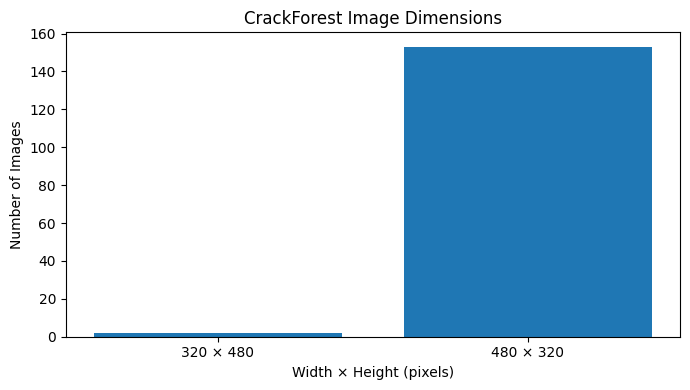

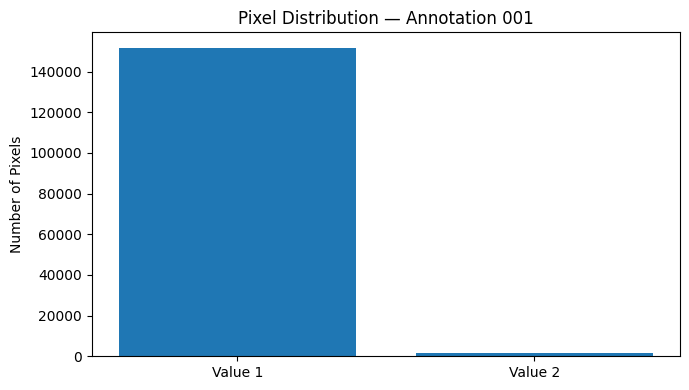


EDA outputs saved in: /content/InfraScan/eda_results


In [ ]:
# Dataset-level statistics for CrackForest

image_files = sorted(image_dir.glob("*.jpg"))
mat_files = sorted(ground_truth_dir.glob("*.mat"))
seg_files = sorted(seg_dir.glob("*.seg"))

image_stems = {p.stem for p in image_files}
mat_stems = {p.stem for p in mat_files}
seg_stems = {p.stem for p in seg_files}

dataset_summary = pd.DataFrame([
    {"Metric": "Total JPG images", "Value": len(image_files)},
    {"Metric": "Ground-truth MAT files", "Value": len(mat_files)},
    {"Metric": "SEG files", "Value": len(seg_files)},
    {"Metric": "Images with matching MAT annotation", "Value": len(image_stems & mat_stems)},
    {"Metric": "Images without matching MAT annotation", "Value": len(image_stems - mat_stems)},
    {"Metric": "Images with matching SEG file", "Value": len(image_stems & seg_stems)},
    {"Metric": "Unreadable JPG images", "Value": len(unreadable_images)},
])

print("CrackForest dataset summary")
display(dataset_summary)

print("\nImage dimensions:")
dimension_rows = []

for path in image_files:
    with Image.open(path) as img:
        dimension_rows.append({
            "filename": path.name,
            "width": img.width,
            "height": img.height,
            "mode": img.mode
        })

image_df = pd.DataFrame(dimension_rows)
display(
    image_df.groupby(["width", "height", "mode"])
    .size()
    .reset_index(name="image_count")
)

# Annotation coverage by filename
coverage_df = pd.DataFrame({
    "filename": sorted(image_stems)
})
coverage_df["has_ground_truth_mat"] = coverage_df["filename"].isin(mat_stems)
coverage_df["has_seg_file"] = coverage_df["filename"].isin(seg_stems)

print("\nAnnotation coverage:")
display(coverage_df[["has_ground_truth_mat", "has_seg_file"]].value_counts().reset_index(name="image_count"))

# Save summaries
dataset_summary.to_csv(EDA_DIR / "crackforest_dataset_summary.csv", index=False)
image_df.to_csv(EDA_DIR / "crackforest_image_summary.csv", index=False)
coverage_df.to_csv(EDA_DIR / "crackforest_annotation_coverage.csv", index=False)

# Plot image dimensions
dimension_counts = (
    image_df.groupby(["width", "height"])
    .size()
    .reset_index(name="count")
)
dimension_counts["dimensions"] = (
    dimension_counts["width"].astype(str)
    + " × "
    + dimension_counts["height"].astype(str)
)

plt.figure(figsize=(7, 4))
plt.bar(dimension_counts["dimensions"], dimension_counts["count"])
plt.title("CrackForest Image Dimensions")
plt.xlabel("Width × Height (pixels)")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(EDA_DIR / "crackforest_image_dimensions.png", dpi=150)
plt.show()

# Plot ground-truth pixel distribution for the sample annotation
sample_annotation = annotation_df.iloc[0]

plt.figure(figsize=(7, 4))
plt.bar(
    ["Value 1", "Value 2"],
    [
        sample_annotation["segmentation_value_1_pixels"],
        sample_annotation["segmentation_value_2_pixels"]
    ]
)
plt.title("Pixel Distribution — Annotation 001")
plt.ylabel("Number of Pixels")
plt.tight_layout()
plt.savefig(EDA_DIR / "crackforest_sample_pixel_distribution.png", dpi=150)
plt.show()

print("\nEDA outputs saved in:", EDA_DIR)

### Dataset 4: CrackForest Dataset (CFD) — EDA Summary

**Purpose:** Road-surface crack segmentation using original road images and pixel-level ground-truth annotations.

**Dataset structure**

- Original images: 155 JPG files and one additional RAR archive in the `image` folder.
- Ground-truth anCrackForest dataset summary

  |       |                             **Metric** | **Value** |
  | ----: | -------------------------------------: | --------: |
  | **0** |                       Total JPG images |       155 |
  | **1** |                 Ground-truth MAT files |       118 |
  | **2** |                              SEG files |       118 |
  | **3** |    Images with matching MAT annotation |       118 |
  | **4** | Images without matching MAT annotation |        37 |
  | **5** |          Images with matching SEG file |       118 |
  | **6** |                  Unreadable JPG images |         0 |
  ```
  Image dimensions:

  ```
  |       | **width** | **height** | **mode** | **image_count** |
  | ----: | --------: | ---------: | -------: | --------------: |
  | **0** |       320 |        480 |      RGB |               2 |
  | **1** |       480 |        320 |      RGB |             153 |
  ```
  Annotation coverage:

  ```
  |       | **has_ground_truth_mat** | **has_seg_file** | **image_count** |
  | ----: | -----------------------: | ---------------: | --------------: |
  | **0** |                     True |             True |             118 |
  | **1** |                    False |            False |              37 |
  ```
  EDA outputs saved in: /content/InfraScan/eda_results
  ```
  notations: 118 MATLAB `.mat` files.
- Segmentation files: 118 `.seg` files.
- All 118 ground-truth annotations have matching JPG images and matching `.seg` filenames.

**Image quality and dimensions**

- All 155 JPG images were readable during inspection.
- 153 images have dimensions of 480 × 320 pixels.
- 2 images have dimensions of 320 × 480 pixels.
- All 118 MATLAB segmentation annotations have dimensions of 320 × 480 pixels.

**Ground-truth observations**

- MATLAB annotations contain `Segmentation` and `Boundaries` fields.
- All inspected boundary maps contain pixel values 0 and 1.
- Segmentation maps contain values 1 and 2 in 96 annotations, values 1, 2, and 3 in 17 annotations, and values 1, 2, 3, and 4 in 5 annotations.
- Sample visualizations show the correspondence between original road images, segmentation annotations, and boundary maps.

**Limitations**

- The 37 JPG images without matching `.mat` annotations require separate inspection before being included in supervised segmentation training.
- The meaning of each segmentation value should be confirmed from the dataset documentation before mapping it to crack and background classes.
- The extra RAR archive and the `.seg` file format have not yet been independently inspected.
- Image readability was checked for the 155 JPG files; no unreadable JPGs were found.

**Conclusion:** CrackForest provides pixel-level annotations suitable for crack segmentation research. Before model training, confirm the annotation semantics, inspect the additional files, and define a consistent image–mask pairing strategy.

**Usage restriction:** The repository states that the dataset is made available for non-commercial research purposes only. Review the repository's terms and citation requirements before using or redistributing the data.


# Dataset 4

In [ ]:
# Dataset 4: Crack500 workspace

DATASET5_DIR = DATA_DIR / "Crack500"
DATASET5_RAW_DIR = DATASET5_DIR / "raw"
DATASET5_IMAGES_DIR = DATASET5_DIR / "images"
DATASET5_MASKS_DIR = DATASET5_DIR / "masks"

for directory in [
    DATASET5_RAW_DIR,
    DATASET5_IMAGES_DIR,
    DATASET5_MASKS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Crack500 workspace initialized.")
print("Raw archive directory:", DATASET5_RAW_DIR)
print("Images directory:", DATASET5_IMAGES_DIR)
print("Masks directory:", DATASET5_MASKS_DIR)

Crack500 workspace initialized.
Raw archive directory: /content/InfraScan/datasets/Crack500/raw
Images directory: /content/InfraScan/datasets/Crack500/images
Masks directory: /content/InfraScan/datasets/Crack500/masks


In [ ]:
from pathlib import Path
import shutil
import zipfile

DATASET5_RAW_DIR.mkdir(parents=True, exist_ok=True)

source = Path("/content/archive.zip")
archive_path = DATASET5_RAW_DIR / "archive.zip"

if source.exists():
    if source.resolve() != archive_path.resolve():
        shutil.move(str(source), str(archive_path))
elif not archive_path.exists():
    raise FileNotFoundError(
        "archive.zip not found. Check the Colab upload."
    )

print("Archive:", archive_path)
print(f"Size: {archive_path.stat().st_size / (1024**2):.2f} MiB")
print("Valid ZIP:", zipfile.is_zipfile(archive_path))

if zipfile.is_zipfile(archive_path):
    with zipfile.ZipFile(archive_path, "r") as z:
        entries = z.namelist()
        print("Total archive entries:", len(entries))
        print("\nFirst 30 entries:")
        print("\n".join(entries[:30]))

Archive: /content/InfraScan/datasets/Crack500/raw/archive.zip
Size: 1567.07 MiB
Valid ZIP: True
Total archive entries: 10487

First 30 entries:
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1281.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1281.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1921.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_1921.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_641.mat
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_361_641.png
CRACK500/fphb_testresult/hed_fuse_fpn_ada_python_v1_iter_12000/20160222_080933_721_1.mat
CRACK500/fphb_testresult/hed_fuse_fpn_a

In [ ]:
import zipfile
from collections import Counter

with zipfile.ZipFile(archive_path, "r") as z:
    entries = z.namelist()

    # Top-level directories
    top_level = Counter(
        name.split("/")[1]
        for name in entries
        if name.startswith("CRACK500/") and len(name.split("/")) > 2
    )

    print("Top-level folders inside CRACK500:")
    for folder, count in sorted(top_level.items()):
        print(f"{folder}: {count} entries")

    # File extension counts
    extensions = Counter(
        Path(name).suffix.lower()
        for name in entries
        if name and not name.endswith("/")
    )

    print("\nFile counts by extension:")
    for ext, count in extensions.most_common():
        print(f"{ext or '[no extension]'}: {count}")

    # Show paths containing likely dataset split names
    print("\nPaths containing train/val/test/crop:")
    matches = [
        name for name in entries
        if any(word in name.lower() for word in ["traincrop", "valcrop", "testcrop"])
        and not name.endswith("/")
    ]
    print("\n".join(matches[:30]) if matches else "No matching paths found.")

Top-level folders inside CRACK500:
fphb_testresult: 2248 entries
testcrop: 2248 entries
testdata: 600 entries
traincrop: 3792 entries
traindata: 800 entries
valcrop: 696 entries
valdata: 100 entries

File counts by extension:
.png: 4992
.jpg: 3868
.mat: 1124
.txt: 503

Paths containing train/val/test/crop:
CRACK500/testcrop/testcrop/20160222_080933_361_1.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1.png
CRACK500/testcrop/testcrop/20160222_080933_361_1281.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1281.png
CRACK500/testcrop/testcrop/20160222_080933_361_1921.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_1921.png
CRACK500/testcrop/testcrop/20160222_080933_361_641.jpg
CRACK500/testcrop/testcrop/20160222_080933_361_641.png
CRACK500/testcrop/testcrop/20160222_080933_721_1.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_1.png
CRACK500/testcrop/testcrop/20160222_080933_721_1921.jpg
CRACK500/testcrop/testcrop/20160222_080933_721_1921.png
CRACK500/testcrop/testcrop/2016022

In [ ]:
import zipfile
from collections import Counter, defaultdict
from pathlib import PurePosixPath

with zipfile.ZipFile(archive_path, "r") as z:
    entries = [
        name for name in z.namelist()
        if name.startswith("CRACK500/")
        and not name.endswith("/")
    ]

    for folder in ["traincrop", "valcrop", "testcrop"]:
        files = [
            name for name in entries
            if f"CRACK500/{folder}/" in name
        ]

        extensions = Counter(
            PurePosixPath(name).suffix.lower()
            for name in files
        )

        stems_by_ext = defaultdict(set)
        for name in files:
            path = PurePosixPath(name)
            stems_by_ext[path.suffix.lower()].add(
                str(path.with_suffix(""))
            )

        jpg_stems = stems_by_ext[".jpg"]
        png_stems = stems_by_ext[".png"]

        print(f"\n{folder}")
        print("Files by extension:", dict(extensions))
        print("JPG images:", len(jpg_stems))
        print("PNG files:", len(png_stems))
        print("Matching JPG/PNG stems:", len(jpg_stems & png_stems))
        print("JPG without matching PNG:", len(jpg_stems - png_stems))
        print("PNG without matching JPG:", len(png_stems - jpg_stems))
        print("Sample filenames:")
        print("\n".join(files[:6]))


traincrop
Files by extension: {'.jpg': 1896, '.png': 1896}
JPG images: 1896
PNG files: 1896
Matching JPG/PNG stems: 1896
JPG without matching PNG: 0
PNG without matching JPG: 0
Sample filenames:
CRACK500/traincrop/traincrop/20160222_081011_1281_721.jpg
CRACK500/traincrop/traincrop/20160222_081011_1281_721.png
CRACK500/traincrop/traincrop/20160222_081011_1921_721.jpg
CRACK500/traincrop/traincrop/20160222_081011_1921_721.png
CRACK500/traincrop/traincrop/20160222_081011_1_361.jpg
CRACK500/traincrop/traincrop/20160222_081011_1_361.png

valcrop
Files by extension: {'.jpg': 348, '.png': 348}
JPG images: 348
PNG files: 348
Matching JPG/PNG stems: 348
JPG without matching PNG: 0
PNG without matching JPG: 0
Sample filenames:
CRACK500/valcrop/valcrop/20160222_080850_1281_361.jpg
CRACK500/valcrop/valcrop/20160222_080850_1281_361.png
CRACK500/valcrop/valcrop/20160222_080850_1281_721.jpg
CRACK500/valcrop/valcrop/20160222_080850_1281_721.png
CRACK500/valcrop/valcrop/20160222_080850_1921_1.jpg
CRACK

In [ ]:
#extraction of dataset
import zipfile

DATASET5_EXTRACT_DIR = DATASET5_DIR / "source"
DATASET5_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

folders_to_extract = [
    "CRACK500/traincrop/",
    "CRACK500/valcrop/",
    "CRACK500/testcrop/",
]

with zipfile.ZipFile(archive_path, "r") as z:
    selected_entries = [
        name for name in z.namelist()
        if any(name.startswith(folder) for folder in folders_to_extract)
    ]

    print("Entries to extract:", len(selected_entries))

    for name in selected_entries:
        z.extract(name, DATASET5_EXTRACT_DIR)

print("Extraction completed.")
print("Dataset location:", DATASET5_EXTRACT_DIR)

Entries to extract: 6736
Extraction completed.
Dataset location: /content/InfraScan/datasets/Crack500/source


train: 1896 JPG, 1896 PNG
validation: 348 JPG, 348 PNG
test: 1124 JPG, 1124 PNG

Sample image: 20160222_081011_1281_721.jpg
Image dimensions: (640, 360)
Mask dimensions: (360, 640)
Mask mode: 1
Mask unique values (up to 20): [False  True]


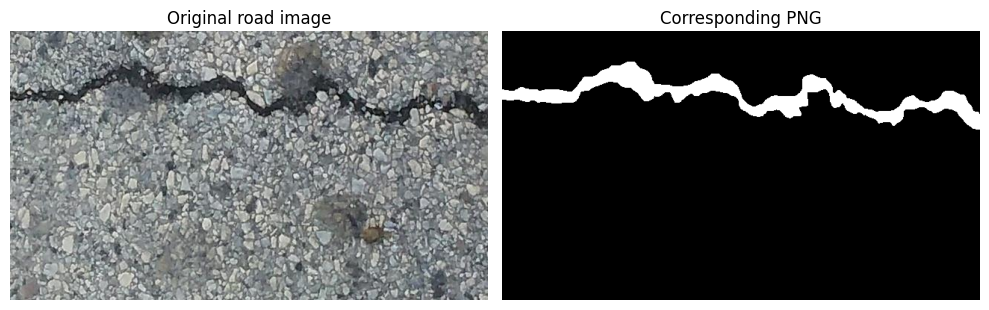

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

dataset5_root = DATASET5_EXTRACT_DIR / "CRACK500"

split_dirs = {
    "train": dataset5_root / "traincrop" / "traincrop",
    "validation": dataset5_root / "valcrop" / "valcrop",
    "test": dataset5_root / "testcrop" / "testcrop",
}

for split, folder in split_dirs.items():
    jpg_count = len(list(folder.glob("*.jpg")))
    png_count = len(list(folder.glob("*.png")))
    print(f"{split}: {jpg_count} JPG, {png_count} PNG")

# Visual inspection of one training pair
train_dir = split_dirs["train"]
sample_image_path = sorted(train_dir.glob("*.jpg"))[0]
sample_mask_path = sample_image_path.with_suffix(".png")

with Image.open(sample_image_path) as img:
    original = img.convert("RGB").copy()

with Image.open(sample_mask_path) as mask:
    mask_array = np.array(mask)

print("\nSample image:", sample_image_path.name)
print("Image dimensions:", original.size)
print("Mask dimensions:", mask_array.shape)
print("Mask mode:", Image.open(sample_mask_path).mode)
print("Mask unique values (up to 20):", np.unique(mask_array)[:20])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(original)
axes[0].set_title("Original road image")
axes[0].axis("off")

axes[1].imshow(mask_array, cmap="gray")
axes[1].set_title("Corresponding PNG")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Split summary:


,split,jpg_images,png_masks,matched_pairs
0,train,1896,1896,1896
1,validation,348,348,348
2,test,1124,1124,1124



Image dimensions by split:


,split,width,height,mode,count
0,test,360,640,RGB,19
1,test,640,360,RGB,1105
2,train,360,640,RGB,86
3,train,640,360,RGB,1754
4,train,648,484,RGB,56
5,validation,360,640,RGB,7
6,validation,640,360,RGB,324
7,validation,648,484,RGB,17



Mask dimensions and modes:


,split,width,height,mode,count
0,test,360,640,1,19
1,test,640,360,1,1105
2,train,360,640,1,86
3,train,640,360,1,1754
4,train,648,484,1,56
5,validation,360,640,1,7
6,validation,640,360,1,324
7,validation,648,484,1,17



Mask pixel-value combinations:


,split,unique_values,count
0,test,"False,True",1124
1,train,"False,True",1896
2,validation,"False,True",348



Image/mask issues found: 0


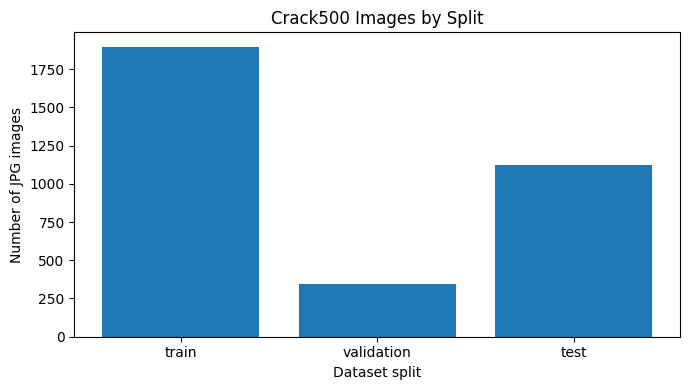


EDA outputs saved in: /content/InfraScan/eda_results


In [ ]:
from PIL import Image
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Analyze each split
image_rows = []
mask_rows = []
pair_errors = []

for split, folder in split_dirs.items():
    jpg_files = sorted(folder.glob("*.jpg"))
    png_files = sorted(folder.glob("*.png"))

    jpg_stems = {p.stem for p in jpg_files}
    png_stems = {p.stem for p in png_files}

    for stem in sorted(jpg_stems - png_stems):
        pair_errors.append({"split": split, "filename": stem, "issue": "Missing PNG mask"})

    for stem in sorted(png_stems - jpg_stems):
        pair_errors.append({"split": split, "filename": stem, "issue": "Missing JPG image"})

    for image_path in jpg_files:
        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                width, height = img.size
                mode = img.mode

            image_rows.append({
                "split": split,
                "filename": image_path.name,
                "width": width,
                "height": height,
                "mode": mode
            })
        except Exception as exc:
            pair_errors.append({
                "split": split,
                "filename": image_path.name,
                "issue": f"Unreadable JPG: {type(exc).__name__}"
            })

    for mask_path in png_files:
        try:
            with Image.open(mask_path) as mask:
                mask.verify()

            with Image.open(mask_path) as mask:
                mask_array = np.asarray(mask)
                width, height = mask.size
                unique_values = np.unique(mask_array)
                mask_mode = mask.mode

            mask_rows.append({
                "split": split,
                "filename": mask_path.name,
                "width": width,
                "height": height,
                "mode": mask_mode,
                "unique_values": ",".join(map(str, unique_values.tolist())),
                "foreground_pixels": int(np.count_nonzero(mask_array)),
                "total_pixels": int(mask_array.size)
            })

            if width != height and (width, height) != (640, 360):
                pass  # Dimensions are recorded for inspection below.

        except Exception as exc:
            pair_errors.append({
                "split": split,
                "filename": mask_path.name,
                "issue": f"Unreadable PNG: {type(exc).__name__}"
            })

image_df = pd.DataFrame(image_rows)
mask_df = pd.DataFrame(mask_rows)
errors_df = pd.DataFrame(pair_errors)

# Split-level summary
split_summary = pd.DataFrame([
    {
        "split": split,
        "jpg_images": len(list(folder.glob("*.jpg"))),
        "png_masks": len(list(folder.glob("*.png"))),
        "matched_pairs": len(
            {p.stem for p in folder.glob("*.jpg")}
            & {p.stem for p in folder.glob("*.png")}
        )
    }
    for split, folder in split_dirs.items()
])

print("Split summary:")
display(split_summary)

print("\nImage dimensions by split:")
display(
    image_df.groupby(["split", "width", "height", "mode"])
    .size().reset_index(name="count")
)

print("\nMask dimensions and modes:")
display(
    mask_df.groupby(["split", "width", "height", "mode"])
    .size().reset_index(name="count")
)

print("\nMask pixel-value combinations:")
display(
    mask_df.groupby(["split", "unique_values"])
    .size().reset_index(name="count")
)

print("\nImage/mask issues found:", len(errors_df))
if not errors_df.empty:
    display(errors_df.head(20))

# Save EDA tables
split_summary.to_csv(EDA_DIR / "crack500_split_summary.csv", index=False)
image_df.to_csv(EDA_DIR / "crack500_image_summary.csv", index=False)
mask_df.to_csv(EDA_DIR / "crack500_mask_summary.csv", index=False)
errors_df.to_csv(EDA_DIR / "crack500_validation_issues.csv", index=False)

# Plot image counts by split
plt.figure(figsize=(7, 4))
plt.bar(split_summary["split"], split_summary["jpg_images"])
plt.title("Crack500 Images by Split")
plt.xlabel("Dataset split")
plt.ylabel("Number of JPG images")
plt.tight_layout()
plt.savefig(EDA_DIR / "crack500_split_distribution.png", dpi=150)
plt.show()

print("\nEDA outputs saved in:", EDA_DIR)

### Dataset 4: Crack500 — EDA Summary

**Purpose:** Pixel-level road-crack segmentation using road images and corresponding binary masks.

**Dataset structure**
- Training: 1,896 JPG images and 1,896 PNG masks.
- Validation: 348 JPG images and 348 PNG masks.
- Test: 1,124 JPG images and 1,124 PNG masks.
- Total: 3,368 matched image–mask pairs.
- All image filenames matched their corresponding mask filenames in the inspected crop splits.

**Image quality and dimensions**
- No unreadable JPG images or PNG masks were detected during validation.
- Image and mask dimensions matched within each split.
- Observed dimensions were 640 × 360, 360 × 640, and 648 × 484 pixels.
- Most images were 640 × 360 pixels.

**Ground-truth observations**
- PNG masks were stored in binary mode (`1`).
- All masks in each split contained two pixel values, represented as `False` and `True` by NumPy.
- Visual inspection of a sample confirmed that white pixels represent the crack region and black pixels represent the background.

**Limitations**
- The counts represent the crop splits in the downloaded archive, not necessarily the complete original Crack500 dataset.
- The original images and other archive folders were not included in this initial crop-focused EDA.
- Images with different dimensions will require consistent preprocessing before model training.

**Conclusion:** Crack500 provides paired road images and binary crack masks suitable for segmentation experiments. The checked crop splits have complete filename pairing and no detected file-validation issues.

**EDA outputs:** Saved in `/content/InfraScan/eda_results`.
